In [8]:
#Linear Regression: Simple, Multiple, Assumptions, and Evaluation


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import scipy.stats as stats

# Set random seed for reproducibility
np.random.seed(42)

# Generate synthetic dataset
n_samples = 200
X1 = np.random.normal(5, 2, n_samples)      # Feature 1 (e.g., Square Footage)
X2 = np.random.normal(10, 3, n_samples)     # Feature 2 (e.g., Number of Rooms)
# Target variable with some random noise
y = 15 + 3.5 * X1 + 1.2 * X2 + np.random.normal(0, 1.5, n_samples)

df = pd.DataFrame({'Feature1': X1, 'Feature2': X2, 'Target': y})
display(df.head())

,Feature1,Feature2,Target
0,5.993428,11.073362,46.873392
1,4.723471,11.682354,44.651912
2,6.295377,13.249154,52.940670
3,8.046060,13.161406,59.025367
4,4.531693,5.866992,37.226218


In [9]:
#simple linear regresssiion
# Using Feature1 to predict Target
X_simple = df[['Feature1']]
y_simple = df['Target']

X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(X_simple, y_simple, test_size=0.2, random_state=42)

simple_model = LinearRegression()
simple_model.fit(X_train_s, y_train_s)

y_pred_s = simple_model.predict(X_test_s)

r2_s = r2_score(y_test_s, y_pred_s)
rmse_s = np.sqrt(mean_squared_error(y_test_s, y_pred_s))

print(f"Simple Linear Regression Metrics:")
print(f"R-squared: {r2_s:.4f}")
print(f"RMSE: {rmse_s:.4f}")

Simple Linear Regression Metrics:
R-squared: 0.6421
RMSE: 4.2386


In [10]:
#multiple linear regression
# Using Feature1 and Feature2 to predict Target
X_multi = df[['Feature1', 'Feature2']]
y_multi = df['Target']

X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(X_multi, y_multi, test_size=0.2, random_state=42)

multi_model = LinearRegression()
multi_model.fit(X_train_m, y_train_m)

y_pred_m = multi_model.predict(X_test_m)

r2_m = r2_score(y_test_m, y_pred_m)
rmse_m = np.sqrt(mean_squared_error(y_test_m, y_pred_m))

print(f"Multiple Linear Regression Metrics:")
print(f"R-squared: {r2_m:.4f}")
print(f"RMSE: {rmse_m:.4f}")

Multiple Linear Regression Metrics:
R-squared: 0.9573
RMSE: 1.4635


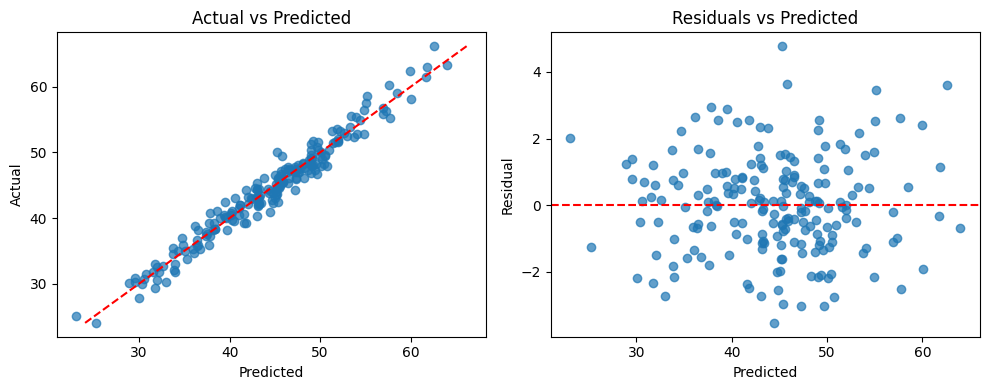

In [13]:
# 1. Fit OLS model with statsmodels
X_with_const = sm.add_constant(X_multi)
model = sm.OLS(y_multi, X_with_const).fit()
predictions = model.predict(X_with_const)
residuals = y_multi - predictions

# 2. Simple plots to check assumptions
plt.figure(figsize=(10, 4))

# Plot 1: Linearity (Actual vs Predicted)
plt.subplot(1, 2, 1)
plt.scatter(predictions, y_multi, alpha=0.7)
plt.plot([y_multi.min(), y_multi.max()], [y_multi.min(), y_multi.max()], 'r--')
plt.title('Actual vs Predicted')
plt.xlabel('Predicted')
plt.ylabel('Actual')

# Plot 2: Homoscedasticity & Residuals
plt.subplot(1, 2, 2)
plt.scatter(predictions, residuals, alpha=0.7)
plt.axhline(0, color='red', linestyle='--')
plt.title('Residuals vs Predicted')
plt.xlabel('Predicted')
plt.ylabel('Residual')

plt.tight_layout()
plt.show()

In [12]:
# 5. Multicollinearity: Variance Inflation Factor (VIF)
vif_data = pd.DataFrame()
vif_data["Feature"] = X_multi.columns
vif_data["VIF"] = [variance_inflation_factor(X_multi.values, i) for i in range(len(X_multi.columns))]
display(vif_data)

,Feature,VIF
0,Feature1,1.009136
1,Feature2,1.009136
